In [1]:
# copy from Starloc.ipynb step 1, for basic info loading
from utils.calibration import CalibrationSignal
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
# iq0_path ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:58:08_freq_11_325G_bw_2.0M_ts_1707177488.0938272_inrx0.dat'
iq0_path ='/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
# date = iq0_path.split('_')[-10]+'_'+iq0_path.split('_')[-9].replace(":","-")
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6

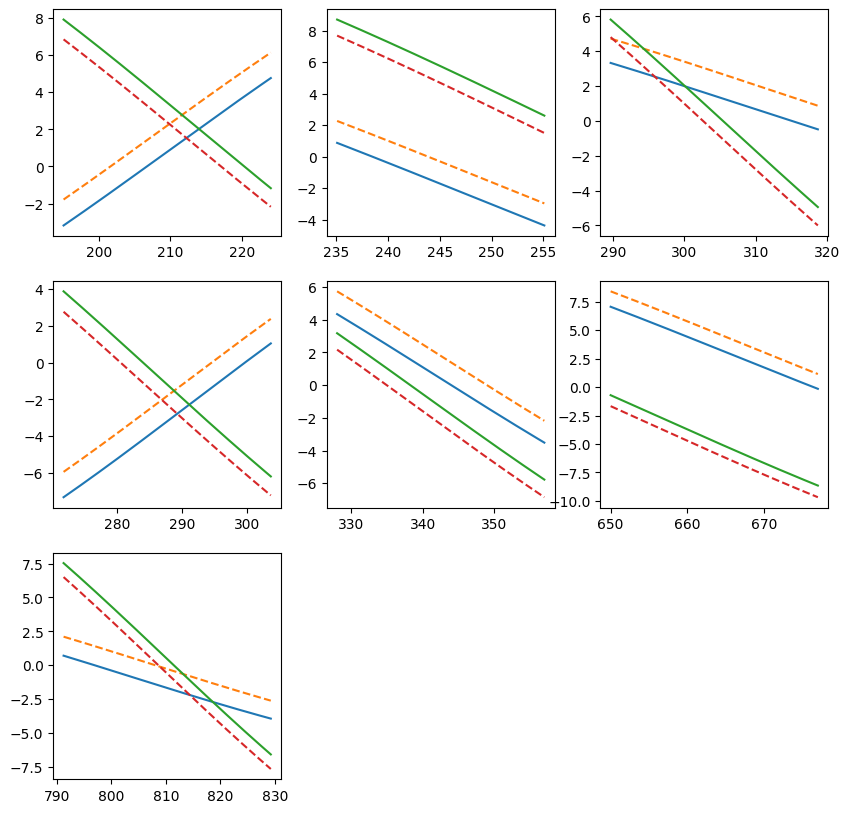

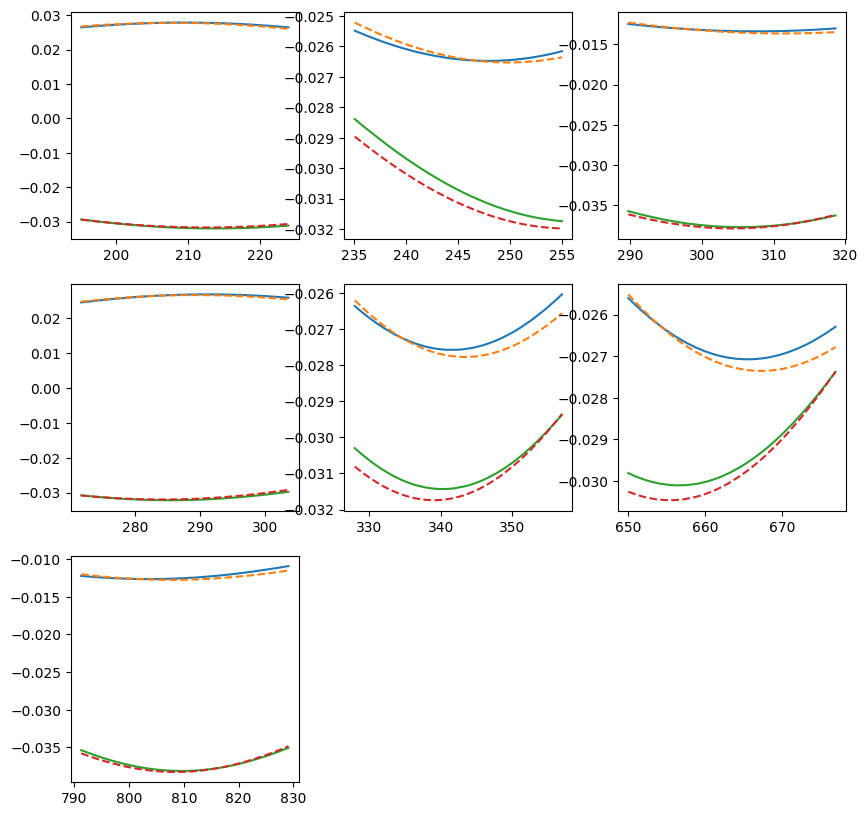

In [15]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat
import random
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
sat_num = len(dopp_track_dict[0, :])

# tracked tones' phase diff
az_gt_list, el_gt_list, t_sim_arr, del_phi_01_gt_list, del_phi_12_gt_list, del_phi_01_list, del_phi_12_list = [], [], [], [], [], [], []
# set d_10, d_12 to be uniform distribution around 13.25e-2
d = 13.25e-2 # meter
d_bound = .0001e-2 # meter
ang_bound = 3 # degree
d_10 = d + random.uniform(-d_bound, d_bound)
d_12 = d + random.uniform(-d_bound, d_bound)
ang_10_1 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
ang_10_2 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
ang_12_1 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
ang_12_2 = np.deg2rad(random.uniform(-ang_bound, ang_bound))

lam = 3e8/fc
loc_1_gt = np.array([0,0,0])   # suppose rx1 is at the origin
loc_0_gt = d_10 * np.array([-np.cos(ang_10_2)*np.sin(ang_10_1), -np.cos(ang_10_2)*np.cos(ang_10_1), -np.sin(ang_10_2)])
loc_2_gt = d_12 * np.array([np.cos(ang_12_2)*np.cos(ang_12_1), -np.cos(ang_12_2)*np.sin(ang_12_1), np.sin(ang_12_2)])
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real

    t_sim, az_gt, el_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin


    range_1_gt = np.linalg.norm(1e7*loc_u-loc_1_gt, axis=1)
    range_0_gt = np.linalg.norm(1e7*loc_u-loc_0_gt, axis=1)
    range_2_gt = np.linalg.norm(1e7*loc_u-loc_2_gt, axis=1)
    del_phi_01_gt = -(range_0_gt-range_1_gt)/lam*2*np.pi
    del_phi_12_gt = -(range_1_gt-range_2_gt)/lam*2*np.pi

    range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
    range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
    range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
    del_phi_01 = -(range_0-range_1)/lam*2*np.pi
    del_phi_12 = -(range_1-range_2)/lam*2*np.pi

    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    del_phi_01_list.append(del_phi_01)
    del_phi_12_list.append(del_phi_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    t_sim_arr.append(t_sim)

# plot a large fig
# plot for phase diff
plt.figure(figsize=(10, 10))
# plt.title('d_10='+str(round(d_10,3))+', d_12='+str(round(d_12,3)))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_01_list[sat_idx], '--')

    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_12_list[sat_idx], '--')
plt.show()
# plot for derivative of phase diff
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_list[sat_idx]), '--')

    plt.plot(t_sim[0:-1], np.diff(del_phi_12_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_12_list[sat_idx]), '--')
plt.show()

In [16]:
# do grid search
from tqdm import tqdm
ang_10_1_grid, ang_10_2_grid = np.linspace(-ang_bound, ang_bound, 200), np.linspace(-ang_bound, ang_bound, 200)
err_min = np.inf
for ang_10_1_search in tqdm(ang_10_1_grid):
    for ang_10_2_search in ang_10_2_grid:
        err = 0
        ang_10_1_search, ang_10_2_search = np.deg2rad(ang_10_1_search), np.deg2rad(ang_10_2_search)
        loc_1 = np.array([0,0,0])   # suppose rx1 is at the origin
        loc_0 = d * np.array([-np.cos(ang_10_2_search)*np.sin(ang_10_1_search), -np.cos(ang_10_2_search)*np.cos(ang_10_1_search), -np.sin(ang_10_2_search)])
        loc_2 = d * np.array([np.cos(ang_12_2)*np.cos(ang_12_1), -np.cos(ang_12_2)*np.sin(ang_12_1), np.sin(ang_12_2)])
        for sat_idx in range(sat_num):
                        
            az_gt, el_gt = az_gt_list[sat_idx], el_gt_list[sat_idx]
            loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
            range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
            range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
            del_phi_01 = -(range_0-range_1)/lam*2*np.pi
            del_phi_12 = -(range_1-range_2)/lam*2*np.pi
            
            err += np.sum(np.abs(del_phi_01-del_phi_01_gt_list[sat_idx]))
            # err += np.sum(np.abs(np.diff(del_phi_01)-np.diff(del_phi_01_gt_list[sat_idx])))
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            ang_min = np.array([ang_10_1_search, ang_10_2_search])


100%|██████████| 200/200 [00:09<00:00, 20.05it/s]


In [17]:
print(ang_min)
print(ang_10_1)
print(ang_10_2)
print(err_min)

[-0.          0.04446643]
-0.004145044102925813
0.044729589489983755
30.576508530768663


In [25]:
for sat_idx in range(sat_num):

    # plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    # plt.plot(t_sim, del_phi_01_list[sat_idx], '--')
    print((del_phi_01_list[sat_idx][-1]-del_phi_01_list[sat_idx][0])/(del_phi_01_gt_list[sat_idx][-1]-del_phi_01_gt_list[sat_idx][0]))

    # plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    # plt.plot(t_sim, del_phi_12_list[sat_idx], '--')
    
    # plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
# plt.show()

0.9819211950794137
0.981921080978797
0.9819211785673801
0.9819211241458984
0.981921092422429
0.9819211635500219
0.9819210896435053
